# Human AChE QSAR — Scaffold-Aware Model Evaluation

**Publication-oriented analysis notebook** · ChEMBL target **CHEMBL220** (UniProt **P22303**)

This notebook reproduces the **revised v2 scaffold split**, molecular features, Extra Trees scaffold cross-validation, classical QSAR baselines, internal holdout assessment, and prediction-error figures from the saved **provisionally curated dataset**. The full exploratory workflow and original ChEMBL/assay-curation code are retained in `AChE_QSAR_Organized.ipynb` (archive; not required for this notebook).

**Interpretation warning:** The revised holdout was not fully untouched across the broader history of model development, and assay provenance remains incompletely verified. These results are **retrospective internal assessment**, not external/prospective validation. Do not tune models using the holdout.

## 1. Setup and input data

Run from the repository root or `notebooks/` directory. Requires `data/processed/AChE_QSAR_provisional.csv`, which is a **derived dataset**, not a fully audited primary experimental resource. All feature calculations are deterministic per molecule; the scaler for linear baselines is fitted separately inside each CV fold.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

ROOT = Path.cwd()
if not (ROOT / 'data' / 'processed' / 'AChE_QSAR_provisional.csv').exists():
    ROOT = ROOT.parent
DATA = ROOT / 'data' / 'processed' / 'AChE_QSAR_provisional.csv'
if not DATA.exists():
    raise FileNotFoundError(f'Missing curated input: {DATA}')
RESULTS = ROOT / 'results'
FIGURES = ROOT / 'figures'
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
qsar_dataset = pd.read_csv(DATA)
assert {'standardized_smiles', 'pIC50'}.issubset(qsar_dataset.columns)
assert len(qsar_dataset) == 3644, 'Input dataset differs from the reported v2 study.'
print('Project:', ROOT)
print('Curated compounds:', len(qsar_dataset))

Project: C:\Users\Hadeer\AChE_QSAR_Research
Curated compounds: 3644


## 2. Molecular representations

Eight RDKit physicochemical descriptors and 2,048-bit Morgan fingerprints (radius 2), with and without stereochemistry. Do **not** use `n_measurements`, `pIC50_min`, `pIC50_max`, or related label-derived columns as features.

In [2]:
DESCRIPTOR_NAMES = ['MW','LogP','TPSA','HBD','HBA','RotatableBonds','RingCount','FractionCSP3']
def calculate_descriptors(m):
    return {
        'MW': Descriptors.MolWt(m),
        'LogP': Descriptors.MolLogP(m),
        'TPSA': rdMolDescriptors.CalcTPSA(m),
        'HBD': rdMolDescriptors.CalcNumHBD(m),
        'HBA': rdMolDescriptors.CalcNumHBA(m),
        'RotatableBonds': rdMolDescriptors.CalcNumRotatableBonds(m),
        'RingCount': rdMolDescriptors.CalcNumRings(m),
        'FractionCSP3': rdMolDescriptors.CalcFractionCSP3(m)
    }
smiles = qsar_dataset['standardized_smiles'].to_numpy()
molecules = [Chem.MolFromSmiles(s) for s in smiles]
assert all(m is not None for m in molecules), 'Invalid SMILES detected.'
descriptor_df = pd.DataFrame([calculate_descriptors(m) for m in molecules], columns=DESCRIPTOR_NAMES)
original_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
chiral_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048, includeChirality=True)
fingerprints = np.asarray([original_gen.GetFingerprintAsNumPy(m) for m in molecules], dtype=np.uint8)
chiral_fingerprints = np.asarray([chiral_gen.GetFingerprintAsNumPy(m) for m in molecules], dtype=np.uint8)
print('Descriptors:', descriptor_df.shape, '| Chiral Morgan:', chiral_fingerprints.shape)

Descriptors: (3644, 8) | Chiral Morgan: (3644, 2048)


## 3. Achiral Murcko scaffold split (v2)

The fixed `GroupShuffleSplit` (seed 42, nominal 20% of scaffold groups) yields **2,830 train / 814 internal holdout compounds**. Both achiral scaffold overlap and non-isomeric connectivity overlap are checked explicitly.

In [3]:
all_scaffolds = np.asarray([MurckoScaffold.MurckoScaffoldSmiles(mol=m, includeChirality=False) for m in molecules])
all_connectivity = np.asarray([Chem.MolToSmiles(m, isomericSmiles=False) for m in molecules])
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, test_idx = next(splitter.split(smiles, qsar_dataset['pIC50'], groups=all_scaffolds))
assert (len(train_idx), len(test_idx)) == (2830, 814)
assert not (set(all_scaffolds[train_idx]) & set(all_scaffolds[test_idx]))
assert not (set(all_connectivity[train_idx]) & set(all_connectivity[test_idx]))
y = qsar_dataset['pIC50'].to_numpy(dtype=float)
y_train, y_test = y[train_idx], y[test_idx]
train_groups = all_scaffolds[train_idx]
X_train = np.hstack([chiral_fingerprints[train_idx].astype(float), descriptor_df.iloc[train_idx].to_numpy(dtype=float)])
X_test = np.hstack([chiral_fingerprints[test_idx].astype(float), descriptor_df.iloc[test_idx].to_numpy(dtype=float)])
assert X_train.shape == (2830, 2056) and X_test.shape == (814, 2056)
print('Train:', len(train_idx), '| Holdout:', len(test_idx), '| Train scaffolds:', len(set(train_groups)))

Train: 2830 | Holdout: 814 | Train scaffolds: 1293


## 4. Extra Trees: five-fold scaffold cross-validation

This is the **frozen exploratory selection**, not a new hyperparameter search. The fold means are reported separately from the internal holdout. Depending on hardware, fitting 1,500 trees in total may take several minutes.

In [4]:
def new_model():
    return ExtraTreesRegressor(n_estimators=300, min_samples_split=2, min_samples_leaf=1,
                               max_features='sqrt', max_depth=None, random_state=42, n_jobs=-1)
folds = list(GroupKFold(n_splits=5).split(X_train, y_train, groups=train_groups))
cv_rows = []
for k, (fit_idx, val_idx) in enumerate(folds, 1):
    model = new_model()
    model.fit(X_train[fit_idx], y_train[fit_idx])
    pred = model.predict(X_train[val_idx])
    cv_rows.append({'Fold':k, 'R2':r2_score(y_train[val_idx], pred),
                    'RMSE':np.sqrt(mean_squared_error(y_train[val_idx], pred)),
                    'MAE':mean_absolute_error(y_train[val_idx], pred)})
cv_table = pd.DataFrame(cv_rows)
cv_table.to_csv(RESULTS / 'Publish_v2_ExtraTrees_scaffold_cv.csv', index=False)
display(cv_table.round(3))
print('CV means:', cv_table[['R2','RMSE','MAE']].mean().round(3).to_dict())

,Fold,R2,RMSE,MAE
0,1,0.539,0.805,0.617
1,2,0.552,0.782,0.575
2,3,0.623,0.757,0.550
3,4,0.585,0.845,0.619
4,5,0.574,0.826,0.620


CV means: {'R2': 0.575, 'RMSE': 0.803, 'MAE': 0.596}


## 5. Classical QSAR baselines: MLR and PLS

Only the eight physicochemical descriptors are used for these baselines. This compares **complete feature–model pipelines**, not algorithms under identical inputs. PLS component choices are exploratory; the CV means should not be interpreted as unbiased performance after selection.

In [5]:
X_desc_train = descriptor_df.iloc[train_idx].to_numpy(dtype=float)
classical_models = {
    'MLR': make_pipeline(StandardScaler(), LinearRegression()),
    'PLS_2': make_pipeline(StandardScaler(), PLSRegression(n_components=2)),
    'PLS_4': make_pipeline(StandardScaler(), PLSRegression(n_components=4)),
    'PLS_6': make_pipeline(StandardScaler(), PLSRegression(n_components=6))
}
rows = []
for name, estimator in classical_models.items():
    scores = cross_validate(estimator, X_desc_train, y_train, cv=folds,
        scoring={'R2':'r2', 'RMSE':'neg_root_mean_squared_error', 'MAE':'neg_mean_absolute_error'}, n_jobs=1)
    rows.append({'Model':name, 'Mean_R2':scores['test_R2'].mean(),
                 'Mean_RMSE':-scores['test_RMSE'].mean(), 'Mean_MAE':-scores['test_MAE'].mean()})
classical_table = pd.DataFrame(rows)
classical_table.to_csv(RESULTS / 'Publish_v2_MLR_PLS_scaffold_cv.csv', index=False)
display(classical_table.round(3))

,Model,Mean_R2,Mean_RMSE,Mean_MAE
0,MLR,0.164,1.126,0.908
1,PLS_2,0.149,1.137,0.911
2,PLS_4,0.158,1.130,0.910
3,PLS_6,0.162,1.127,0.908


## 6. Revised internal holdout (one fixed evaluation)

The selected Extra Trees configuration is fitted to all v2 training compounds and evaluated on the v2 internal holdout. **Do not use these metrics to select further models.** The holdout was reconstructed after prior exploratory work on the same dataset, so it is not an independent external test.

In [6]:
final_model = new_model()
final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)
metrics = pd.DataFrame([{'Model':'ExtraTrees_ChiralMorgan_Descriptors',
                         'N_Train':len(y_train), 'N_Test':len(y_test),
                         'R2':r2_score(y_test, y_pred),
                         'RMSE':np.sqrt(mean_squared_error(y_test, y_pred)),
                         'MAE':mean_absolute_error(y_test, y_pred)}])
predictions = pd.DataFrame({'standardized_smiles':smiles[test_idx],
                            'pIC50':y_test, 'Predicted_pIC50':y_pred})
predictions['Residual'] = predictions['pIC50'] - predictions['Predicted_pIC50']
predictions['Absolute_Error'] = predictions['Residual'].abs()
metrics.to_csv(RESULTS / 'Publish_v2_holdout_metrics.csv', index=False)
predictions.to_csv(RESULTS / 'Publish_v2_holdout_predictions.csv', index=False)
display(metrics.round(3))

,Model,N_Train,N_Test,R2,RMSE,MAE
0,ExtraTrees_ChiralMorgan_Descriptors,2830,814,0.481,1.011,0.67


## 7. Holdout figures and error concentration

A small highly potent chemical series is substantially underpredicted. This is a **diagnostic observation**, not justification to exclude compounds or report an improved holdout score. The original experimental papers and assay provenance should be reviewed before assigning a chemical or experimental cause.

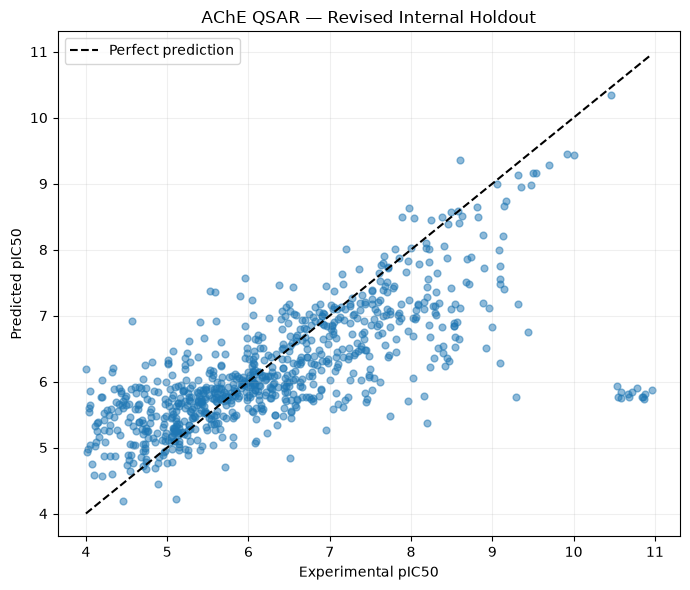

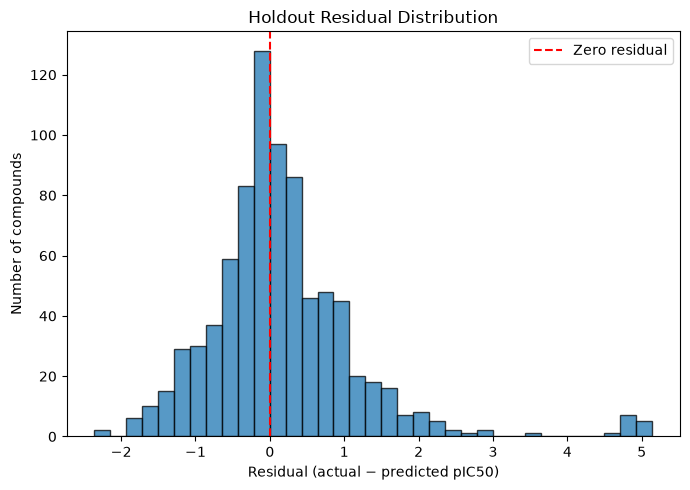

Top 15 compounds: 40.28% of total holdout squared error
Compounds with absolute error > 2: 30


In [7]:
actual = predictions['pIC50'].to_numpy()
predicted = predictions['Predicted_pIC50'].to_numpy()
residual = actual - predicted
fig, ax = plt.subplots(figsize=(7,6))
ax.scatter(actual, predicted, s=24, alpha=.5)
lo, hi = min(actual.min(),predicted.min()), max(actual.max(),predicted.max())
ax.plot([lo,hi],[lo,hi],'k--',label='Perfect prediction')
ax.set(xlabel='Experimental pIC50',ylabel='Predicted pIC50',title='AChE QSAR — Revised Internal Holdout')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout()
fig.savefig(FIGURES/'Final_Actual_vs_Predicted.png',dpi=300)
plt.show()
fig, ax = plt.subplots(figsize=(7,5))
ax.hist(residual,bins=35,edgecolor='black',alpha=.75)
ax.axvline(0,linestyle='--',color='red',label='Zero residual')
ax.set(xlabel='Residual (actual − predicted pIC50)',ylabel='Number of compounds',title='Holdout Residual Distribution')
ax.legend(); fig.tight_layout()
fig.savefig(FIGURES/'Final_Residual_Distribution.png',dpi=300)
plt.show()
sse = np.square(residual)
top15_share = 100 * np.sort(sse)[-15:].sum()/sse.sum()
print(f'Top 15 compounds: {top15_share:.2f}% of total holdout squared error')
print('Compounds with absolute error > 2:', int((np.abs(residual)>2).sum()))

## 8. Reported study results and limitations

The earlier recorded v2 study results were **CV R² 0.575, RMSE 0.803, MAE 0.596** and **internal holdout R² 0.481, RMSE 1.011, MAE 0.670**. Classical baselines were **MLR CV R² 0.164** and **PLS-6 CV R² 0.162**. The 15 largest errors accounted for **40.28%** of holdout squared error. The code above recalculates these quantities from the supplied provisional dataset; compare them against the historical records rather than assuming an exact match across software versions.

**Limitations:** incomplete source-publication/assay harmonization; potential stereochemical activity cliffs and fingerprint limitations; a revised internal holdout previously exposed through exploratory work; no truly independent external or prospective validation. Model predictions must not be treated as experimentally established AChE potency.

**Full provenance:** see the archived exploratory notebook and `data/processed/` curation files. Do not publish raw source records or derived assay-level data without checking licensing and source documentation.